<a href="https://colab.research.google.com/github/alexbedoni95-cpu/Analisi-Climatica-UE-e-Modellazione-Predittiva-2035-Progetto-Finale-EEA-/blob/main/Progetto_finale_aulab_richiesta3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Analisi delle Emissioni di Gas Serra nell'Unione Europea

Procederemo con i seguenti passaggi:
1. Definire un elenco di paesi membri dell'Unione Europea.
2. Caricare i dati relativi alle emissioni di gas serra.
3. Filtrare i dati per includere solo i paesi dell'UE.
4. Identificare i paesi con le emissioni più elevate.
5. Creare grafici chiari e leggibili per visualizzare i risultati.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Elenco dei paesi dell'Unione Europea (aggiornato a 27 membri)
eu_countries = [
    'Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia',
    'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece',
    'Hungary', 'Ireland', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg',
    'Malta', 'Netherlands', 'Poland', 'Portugal', 'Romania', 'Slovakia',
    'Slovenia', 'Spain', 'Sweden'
]


#### 1. Analisi delle Emissioni Totali di Gas Serra (GHG)

Dati GHG_Emissions.csv caricati con successo.


/tmp/ipykernel_1844/3930127539.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Country', y=latest_emission_column, data=df_ghg_eu_sorted, palette='viridis')


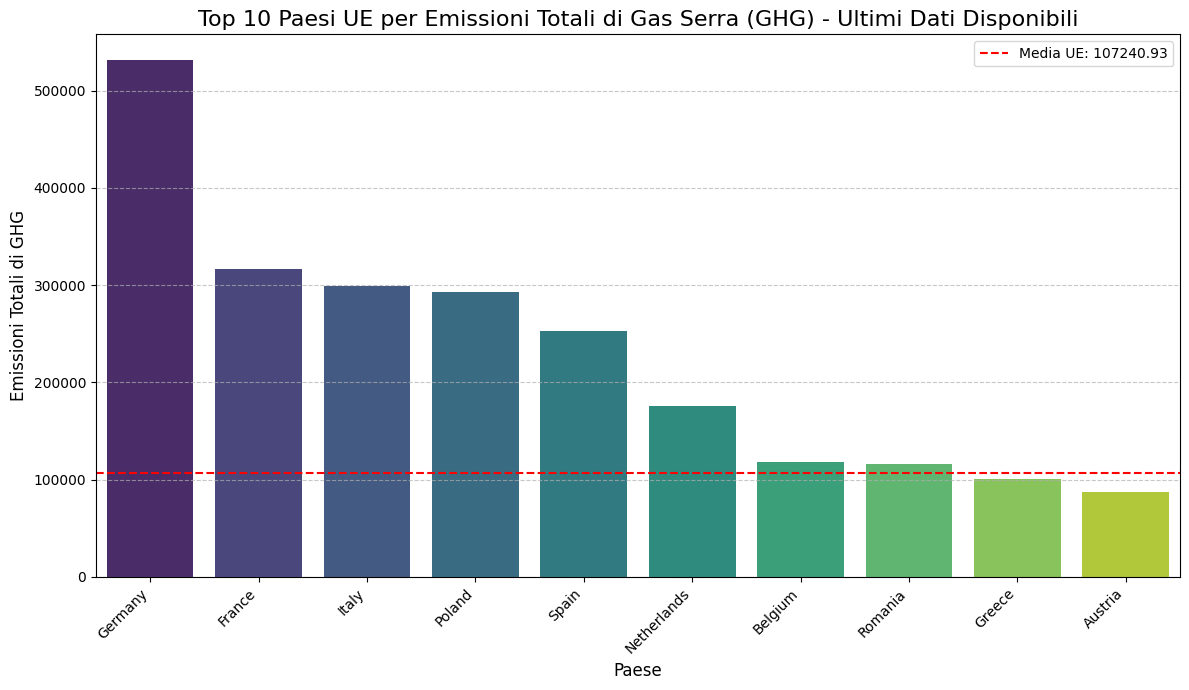

In [ ]:
try:
    df_ghg = pd.read_csv('/content/GHG_Emissions.csv')
    print("Dati GHG_Emissions.csv caricati con successo.")
    # Rinominare le colonne se necessario per coerenza (es. 'Entity' a 'Country')
    if 'Entity' in df_ghg.columns: # Adjust for specific column names in the file
        df_ghg.rename(columns={'Entity': 'Country'}, inplace=True)
    elif 'country' in df_ghg.columns:
        df_ghg.rename(columns={'country': 'Country'}, inplace=True)

    # Filtra per i paesi dell'UE
    df_ghg_eu = df_ghg[df_ghg['Country'].isin(eu_countries)]

    # Trova l'ultima colonna di emissioni (solitamente l'anno più recente)
    # Assumiamo che le colonne di emissioni siano numeriche e rappresentino anni
    emission_columns = df_ghg_eu.select_dtypes(include=['number']).columns.drop('Year', errors='ignore')
    if 'Annual GHG Emissions' in df_ghg_eu.columns: # Common column name for total GHG
        latest_emission_column = 'Annual GHG Emissions'
    elif not emission_columns.empty:
        latest_emission_column = emission_columns[-1]
    else:
        latest_emission_column = None
        print("Colonna delle emissioni non trovata in GHG_Emissions.csv. Si prega di controllare la struttura del file.")

    if latest_emission_column:
        # Aggrega per paese (se ci sono più righe per paese/anno, ad es. diverse categorie)
        df_ghg_eu_agg = df_ghg_eu.groupby('Country')[latest_emission_column].sum().reset_index()
        df_ghg_eu_sorted = df_ghg_eu_agg.sort_values(by=latest_emission_column, ascending=False).head(10)

        # Calcola l'emissione media per tutti i paesi UE mostrati nel grafico
        average_ghg_emissions = df_ghg_eu_agg[latest_emission_column].mean()

        plt.figure(figsize=(12, 7))
        sns.barplot(x='Country', y=latest_emission_column, data=df_ghg_eu_sorted, palette='viridis')
        plt.axhline(average_ghg_emissions, color='red', linestyle='--', label=f'Media UE: {average_ghg_emissions:.2f}')
        plt.title(f'Top 10 Paesi UE per Emissioni Totali di Gas Serra (GHG) - Ultimi Dati Disponibili', fontsize=16)
        plt.xlabel('Paese', fontsize=12)
        plt.ylabel('Emissioni Totali di GHG', fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.legend()
        plt.tight_layout()
        plt.show()

except FileNotFoundError:
    print("Errore: Il file GHG_Emissions.csv non è stato trovato.")
except Exception as e:
    print(f"Si è verificato un errore durante l'elaborazione di GHG_Emissions.csv: {e}")

#### 2. Analisi delle Emissioni di CO2

Dati CO2_Emissions.csv caricati con successo.


/tmp/ipykernel_1844/772658095.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Country', y=latest_emission_column_co2, data=df_co2_eu_sorted, palette='plasma')


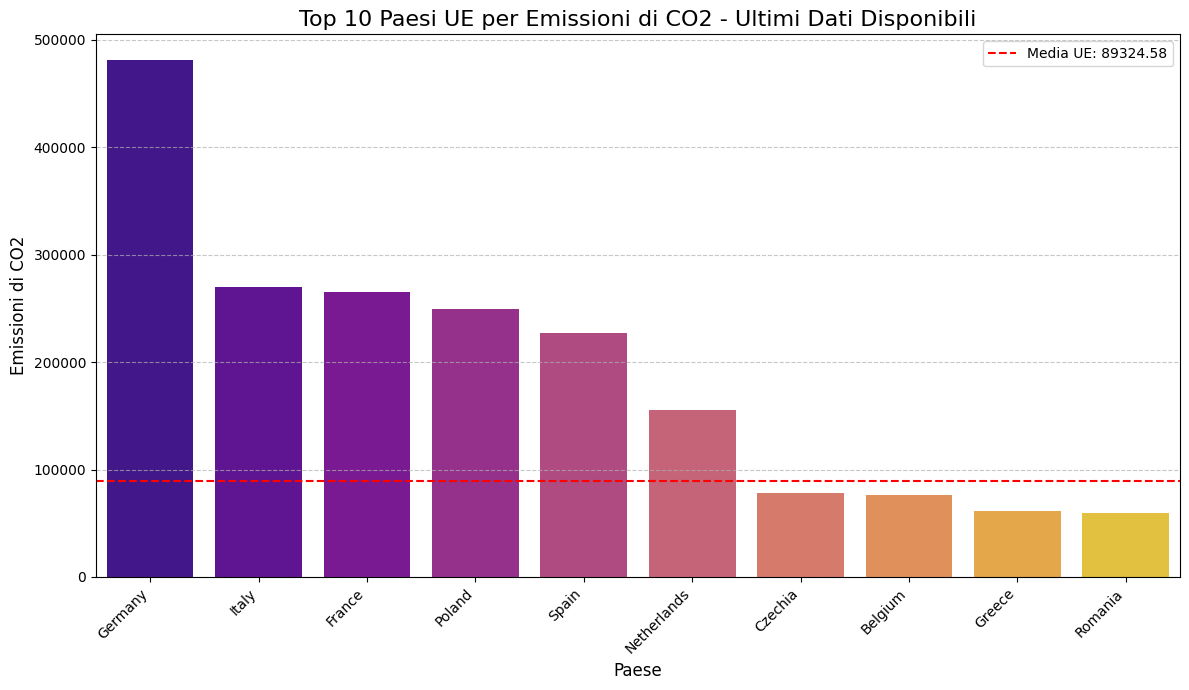

In [ ]:
try:
    df_co2 = pd.read_csv('/content/CO2_Emissions.csv')
    print("Dati CO2_Emissions.csv caricati con successo.")
    if 'Entity' in df_co2.columns:
        df_co2.rename(columns={'Entity': 'Country'}, inplace=True)
    elif 'country' in df_co2.columns:
        df_co2.rename(columns={'country': 'Country'}, inplace=True)

    df_co2_eu = df_co2[df_co2['Country'].isin(eu_countries)]

    emission_columns_co2 = df_co2_eu.select_dtypes(include=['number']).columns.drop('Year', errors='ignore')
    if 'Annual CO2 emissions' in df_co2_eu.columns: # Common column name for CO2
        latest_emission_column_co2 = 'Annual CO2 emissions'
    elif not emission_columns_co2.empty:
        latest_emission_column_co2 = emission_columns_co2[-1]
    else:
        latest_emission_column_co2 = None
        print("Colonna delle emissioni di CO2 non trovata in CO2_Emissions.csv. Si prega di controllare la struttura del file.")

    if latest_emission_column_co2:
        df_co2_eu_agg = df_co2_eu.groupby('Country')[latest_emission_column_co2].sum().reset_index()
        df_co2_eu_sorted = df_co2_eu_agg.sort_values(by=latest_emission_column_co2, ascending=False).head(10)

        # Calcola l'emissione media per tutti i paesi UE mostrati nel grafico
        average_co2_emissions = df_co2_eu_agg[latest_emission_column_co2].mean()

        plt.figure(figsize=(12, 7))
        sns.barplot(x='Country', y=latest_emission_column_co2, data=df_co2_eu_sorted, palette='plasma')
        plt.axhline(average_co2_emissions, color='red', linestyle='--', label=f'Media UE: {average_co2_emissions:.2f}')
        plt.title(f'Top 10 Paesi UE per Emissioni di CO2 - Ultimi Dati Disponibili', fontsize=16)
        plt.xlabel('Paese', fontsize=12)
        plt.ylabel('Emissioni di CO2', fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.legend()
        plt.tight_layout()
        plt.show()

except FileNotFoundError:
    print("Errore: Il file CO2_Emissions.csv non è stato trovato.")
except Exception as e:
    print(f"Si è verificato un errore durante l'elaborazione di CO2_Emissions.csv: {e}")

#### 3. Analisi delle Emissioni di CH4 (Metano)

Dati CH4_Emissions.csv caricati con successo.


/tmp/ipykernel_1844/1082900009.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Country', y=latest_emission_column_ch4, data=df_ch4_eu_sorted, palette='magma')


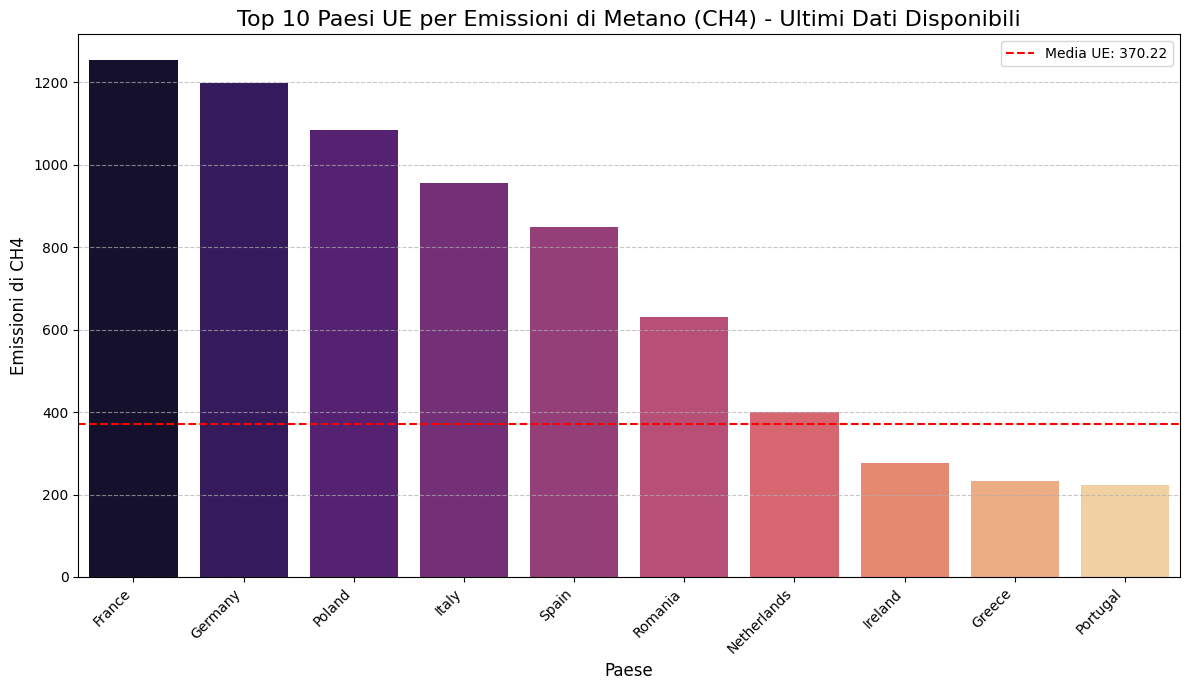

In [ ]:
try:
    df_ch4 = pd.read_csv('/content/CH4_Emissions.csv')
    print("Dati CH4_Emissions.csv caricati con successo.")
    if 'Entity' in df_ch4.columns:
        df_ch4.rename(columns={'Entity': 'Country'}, inplace=True)
    elif 'country' in df_ch4.columns:
        df_ch4.rename(columns={'country': 'Country'}, inplace=True)

    df_ch4_eu = df_ch4[df_ch4['Country'].isin(eu_countries)]

    emission_columns_ch4 = df_ch4_eu.select_dtypes(include=['number']).columns.drop('Year', errors='ignore')
    if 'Annual CH4 emissions' in df_ch4_eu.columns: # Common column name for CH4
        latest_emission_column_ch4 = 'Annual CH4 emissions'
    elif not emission_columns_ch4.empty:
        latest_emission_column_ch4 = emission_columns_ch4[-1]
    else:
        latest_emission_column_ch4 = None
        print("Colonna delle emissioni di CH4 non trovata in CH4_Emissions.csv. Si prega di controllare la struttura del file.")

    if latest_emission_column_ch4:
        df_ch4_eu_agg = df_ch4_eu.groupby('Country')[latest_emission_column_ch4].sum().reset_index()
        df_ch4_eu_sorted = df_ch4_eu_agg.sort_values(by=latest_emission_column_ch4, ascending=False).head(10)

        # Calcola l'emissione media per tutti i paesi UE mostrati nel grafico
        average_ch4_emissions = df_ch4_eu_agg[latest_emission_column_ch4].mean()

        plt.figure(figsize=(12, 7))
        sns.barplot(x='Country', y=latest_emission_column_ch4, data=df_ch4_eu_sorted, palette='magma')
        plt.axhline(average_ch4_emissions, color='red', linestyle='--', label=f'Media UE: {average_ch4_emissions:.2f}')
        plt.title(f'Top 10 Paesi UE per Emissioni di Metano (CH4) - Ultimi Dati Disponibili', fontsize=16)
        plt.xlabel('Paese', fontsize=12)
        plt.ylabel('Emissioni di CH4', fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.legend()
        plt.tight_layout()
        plt.show()

except FileNotFoundError:
    print("Errore: Il file CH4_Emissions.csv non è stato trovato.")
except Exception as e:
    print(f"Si è verificato un errore durante l'elaborazione di CH4_Emissions.csv: {e}")

#### 4. Analisi delle Emissioni di N2O (Protossido di Azoto)

Dati N2O_Emissions.csv caricati con successo.


/tmp/ipykernel_1844/3700844939.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Country', y=latest_emission_column_n2o, data=df_n2o_eu_sorted, palette='cividis')


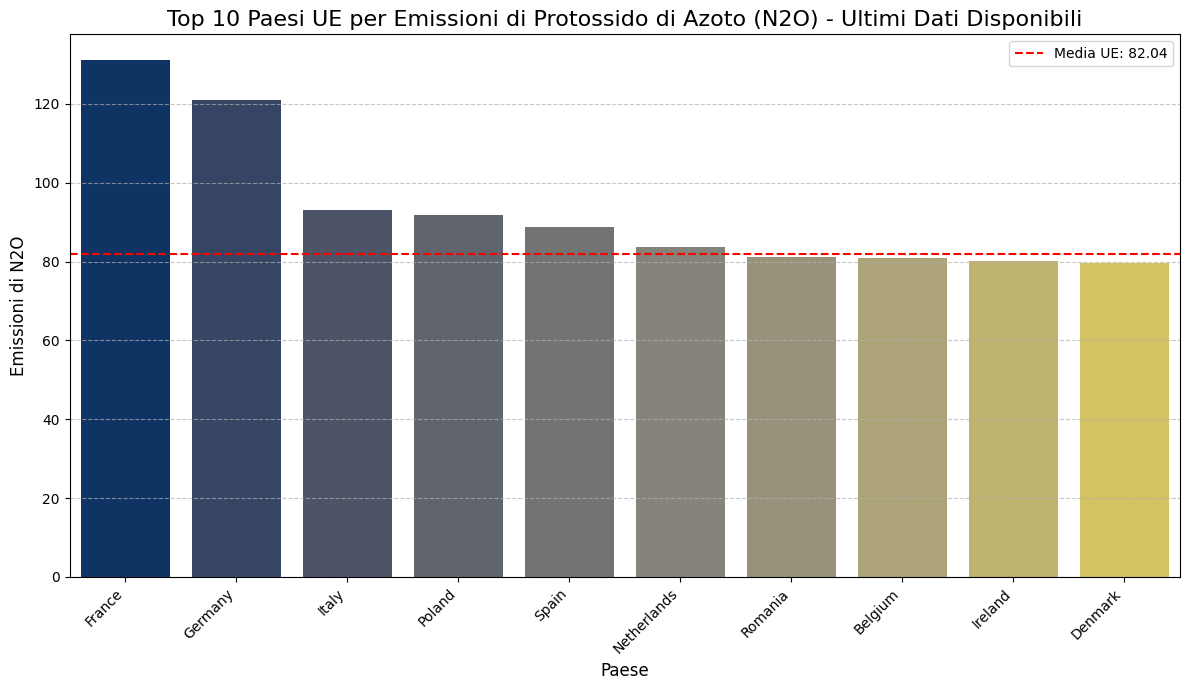

In [ ]:
try:
    df_n2o = pd.read_csv('/content/N2O_Emissions.csv')
    print("Dati N2O_Emissions.csv caricati con successo.")
    if 'Entity' in df_n2o.columns:
        df_n2o.rename(columns={'Entity': 'Country'}, inplace=True)
    elif 'country' in df_n2o.columns:
        df_n2o.rename(columns={'country': 'Country'}, inplace=True)

    df_n2o_eu = df_n2o[df_n2o['Country'].isin(eu_countries)]

    emission_columns_n2o = df_n2o_eu.select_dtypes(include=['number']).columns.drop('Year', errors='ignore')
    if 'Annual N2O emissions' in df_n2o_eu.columns: # Common column name for N2O
        latest_emission_column_n2o = 'Annual N2O emissions'
    elif not emission_columns_n2o.empty:
        latest_emission_column_n2o = emission_columns_n2o[-1]
    else:
        latest_emission_column_n2o = None
        print("Colonna delle emissioni di N2O non trovata in N2O_Emissions.csv. Si prega di controllare la struttura del file.")

    if latest_emission_column_n2o:
        df_n2o_eu_agg = df_n2o_eu.groupby('Country')[latest_emission_column_n2o].sum().reset_index()
        df_n2o_eu_sorted = df_n2o_eu_agg.sort_values(by=latest_emission_column_n2o, ascending=False).head(10)

        # Calcola l'emissione media per tutti i paesi UE mostrati nel grafico
        average_n2o_emissions = df_n2o_eu_agg[latest_emission_column_n2o].mean()

        plt.figure(figsize=(12, 7))
        sns.barplot(x='Country', y=latest_emission_column_n2o, data=df_n2o_eu_sorted, palette='cividis')
        plt.axhline(average_n2o_emissions, color='red', linestyle='--', label=f'Media UE: {average_n2o_emissions:.2f}')
        plt.title(f'Top 10 Paesi UE per Emissioni di Protossido di Azoto (N2O) - Ultimi Dati Disponibili', fontsize=16)
        plt.xlabel('Paese', fontsize=12)
        plt.ylabel('Emissioni di N2O', fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.legend()
        plt.tight_layout()
        plt.show()

except FileNotFoundError:
    print("Errore: Il file N2O_Emissions.csv non è stato trovato.")
except Exception as e:
    print(f"Si è verificato un errore durante l'elaborazione di N2O_Emissions.csv: {e}")

#### 5. Analisi delle Emissioni di SO2 (Diossido di Zolfo)

Dati SO2_emissions.csv caricati con successo.


/tmp/ipykernel_1844/774544579.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Country', y=latest_emission_column_so2, data=df_so2_eu_sorted, palette='inferno')


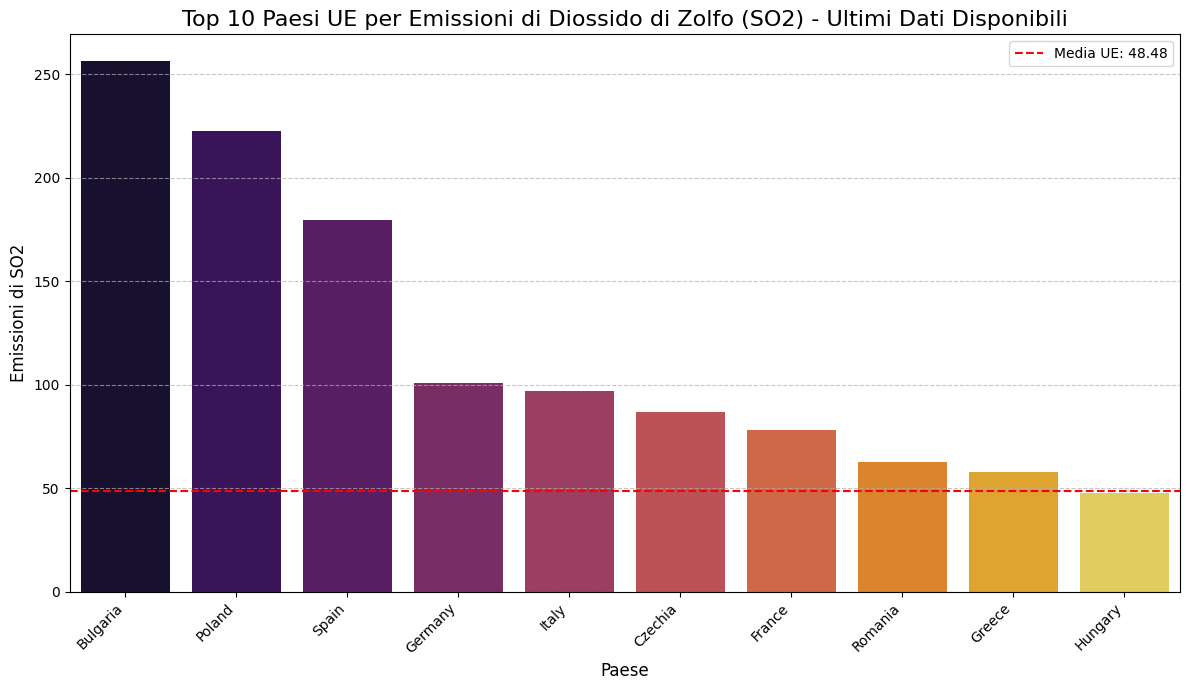

In [ ]:
try:
    df_so2 = pd.read_csv('/content/SO2_emissions.csv')
    print("Dati SO2_emissions.csv caricati con successo.")
    if 'Entity' in df_so2.columns:
        df_so2.rename(columns={'Entity': 'Country'}, inplace=True)
    elif 'country' in df_so2.columns:
        df_so2.rename(columns={'country': 'Country'}, inplace=True)

    df_so2_eu = df_so2[df_so2['Country'].isin(eu_countries)]

    emission_columns_so2 = df_so2_eu.select_dtypes(include=['number']).columns.drop('Year', errors='ignore')
    if 'Annual SO2 emissions' in df_so2_eu.columns: # Common column name for SO2
        latest_emission_column_so2 = 'Annual SO2 emissions'
    elif not emission_columns_so2.empty:
        latest_emission_column_so2 = emission_columns_so2[-1]
    else:
        latest_emission_column_so2 = None
        print("Colonna delle emissioni di SO2 non trovata in SO2_emissions.csv. Si prega di controllare la struttura del file.")

    if latest_emission_column_so2:
        df_so2_eu_agg = df_so2_eu.groupby('Country')[latest_emission_column_so2].sum().reset_index()
        df_so2_eu_sorted = df_so2_eu_agg.sort_values(by=latest_emission_column_so2, ascending=False).head(10)

        # Calcola l'emissione media per tutti i paesi UE mostrati nel grafico
        average_so2_emissions = df_so2_eu_agg[latest_emission_column_so2].mean()

        plt.figure(figsize=(12, 7))
        sns.barplot(x='Country', y=latest_emission_column_so2, data=df_so2_eu_sorted, palette='inferno')
        plt.axhline(average_so2_emissions, color='red', linestyle='--', label=f'Media UE: {average_so2_emissions:.2f}')
        plt.title(f'Top 10 Paesi UE per Emissioni di Diossido di Zolfo (SO2) - Ultimi Dati Disponibili', fontsize=16)
        plt.xlabel('Paese', fontsize=12)
        plt.ylabel('Emissioni di SO2', fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.legend()
        plt.tight_layout()
        plt.show()

except FileNotFoundError:
    print("Errore: Il file SO2_emissions.csv non è stato trovato.")
except Exception as e:
    print(f"Si è verificato un errore durante l'elaborazione di SO2_emissions.csv: {e}")

#### 6. Analisi delle Emissioni di NOx (Ossidi di Azoto)

Dati NOx_Emissions.csv caricati con successo.


/tmp/ipykernel_1844/2731227010.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Country', y=latest_emission_column_nox, data=df_nox_eu_sorted, palette='viridis_r')


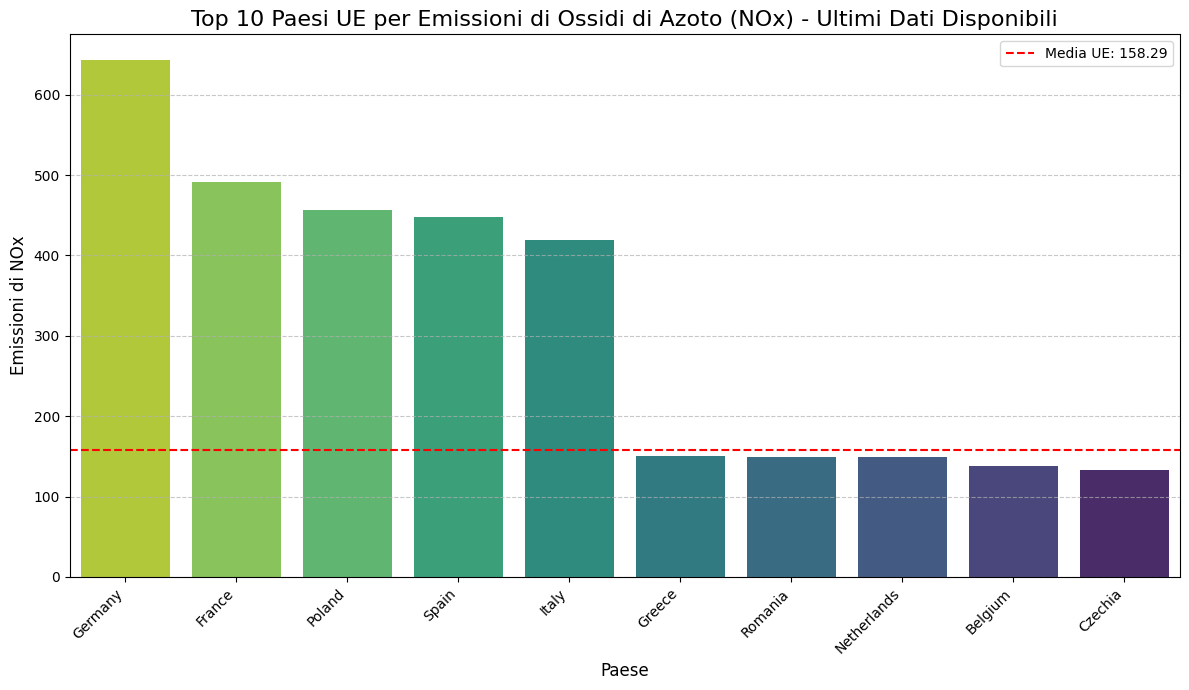

In [ ]:
try:
    df_nox = pd.read_csv('/content/NOx_Emissions.csv')
    print("Dati NOx_Emissions.csv caricati con successo.")
    if 'Entity' in df_nox.columns:
        df_nox.rename(columns={'Entity': 'Country'}, inplace=True)
    elif 'country' in df_nox.columns:
        df_nox.rename(columns={'country': 'Country'}, inplace=True)

    df_nox_eu = df_nox[df_nox['Country'].isin(eu_countries)]

    emission_columns_nox = df_nox_eu.select_dtypes(include=['number']).columns.drop('Year', errors='ignore')
    if 'Annual NOx emissions' in df_nox_eu.columns: # Common column name for NOx
        latest_emission_column_nox = 'Annual NOx emissions'
    elif not emission_columns_nox.empty:
        latest_emission_column_nox = emission_columns_nox[-1]
    else:
        latest_emission_column_nox = None
        print("Colonna delle emissioni di NOx non trovata in NOx_Emissions.csv. Si prega di controllare la struttura del file.")

    if latest_emission_column_nox:
        df_nox_eu_agg = df_nox_eu.groupby('Country')[latest_emission_column_nox].sum().reset_index()
        df_nox_eu_sorted = df_nox_eu_agg.sort_values(by=latest_emission_column_nox, ascending=False).head(10)

        # Calcola l'emissione media per tutti i paesi UE mostrati nel grafico
        average_nox_emissions = df_nox_eu_agg[latest_emission_column_nox].mean()

        plt.figure(figsize=(12, 7))
        sns.barplot(x='Country', y=latest_emission_column_nox, data=df_nox_eu_sorted, palette='viridis_r')
        plt.axhline(average_nox_emissions, color='red', linestyle='--', label=f'Media UE: {average_nox_emissions:.2f}')
        plt.title(f'Top 10 Paesi UE per Emissioni di Ossidi di Azoto (NOx) - Ultimi Dati Disponibili', fontsize=16)
        plt.xlabel('Paese', fontsize=12)
        plt.ylabel('Emissioni di NOx', fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.legend()
        plt.tight_layout()
        plt.show()

except FileNotFoundError:
    print("Errore: Il file NOx_Emissions.csv non è stato trovato.")
except Exception as e:
    print(f"Si è verificato un errore durante l'elaborazione di NOx_Emissions.csv: {e}")